# Deep Convolutional Generative Adversarial Networks con Pytorch.

## Objetivo

El propósito de este laboratorio es que el alumno se familiarice con las redes generativas antagónicas (Generative Adversarial Networks, GANs) a través de un ejemplo. Se entrenará una de estas redes GAN para generar nuevos dígitos manuscritos tras enseñarle múltiples instancias reales de los mismos. Este documento pretende dar una explicación exhaustiva de cómo y por qué funcionan estos modelos.

Las GANs son un _framework_ que nos permite enseñar un modelo de _Deep Learning_ a capturar la distribución de unos datos de manera que pueda generar nuevos datos de la misma distribución. Las GANs fueron inventadas por Ian Goodfellow en 2014 y descritas en la referencia [1]. Se componen de dos modelos distintos:

- El generador, que se especializa en producir datos sintéticos similares a las imaǵenes de entrenamiento reales.
- El discriminador, que a partir de una imagen de entrada se especializa en decidir si es real o sintética.

Ambas redes se entrenan de manera conjunta, de modo que el generador intenta vencer al discriminador generando datos sintéticos cada vez más similares a los reales; y el discriminador intenta diferenciar los datos sintéticos de los reales, mejorando continuamente en esta tarea.


Este tutorial es una adaptación del tutorial disponible en https://pytorch.org/tutorials/beginner/dcgan_faces_tutorial.html.

## Referencias

- [1] GANs. _Generative Adversarial Nets_. https://papers.nips.cc/paper/5423-generative-adversarial-nets.pdf
- [2] Imagen. https://i.blogs.es/bd2b76/gan_arquitectura/1366_2000.jpg
- [3] DCGANs. _Unsupervised Representation Learning With Deep Convolutional Generative Adversarial Networks_. https://arxiv.org/pdf/1511.06434.pdf
- [4] Celeb-A Faces dataset. http://mmlab.ie.cuhk.edu.hk/projects/CelebA.html
- [5] Celeb-A Faces dataset. https://drive.google.com/drive/folders/0B7EVK8r0v71pTUZsaXdaSnZBZzg
- [6] Ganhacks. Best practices to train GANs. https://github.com/soumith/ganhacks
- [7] GAN — Why it is so hard to train Generative Adversarial Networks! https://medium.com/@jonathan_hui/gan-why-it-is-so-hard-to-train-generative-advisory-networks-819a86b3750b
- [8] MNIST handwritten digits database: http://yann.lecun.com/exdb/mnist/
- [9] CIFAR-10 database: https://www.cs.toronto.edu/~kriz/cifar.html

## Antes de empezar

Antes de empezar, necesita configurar algunas cosas en caso de que vaya a utilizar Google Colab. En particular, necesita subir la carpeta que contiene las imágenes de trabajo y cambiar el directorio de trabajo al correspondiente. Para ello, suba la carpeta con la práctica que va a ejecutar (incluyendo la carpeta images) y ejecute el siguiente código:

In [1]:
# Ejecución en local (no en Google Colab): no es necesario montar Google Drive.
# from google.colab import drive
# drive.mount('/content/drive')
import os, sys
print(os.getcwd())

C:\Users\javia\Documents\GitHub\deep-learning-lab02\Lab03


In [2]:
# En local se trabaja en la carpeta del notebook, no hace falta cambiar de directorio.
# os.chdir('/content/drive/My Drive/path/to_gans') #Here put the full path to the folder where you have the images

Además, si quiere ejecutar el código con soporte a GPU, en Google Colab vaya a `Entorno de ejecución->Cambiar tipo entorno de ejecución` y seleccione GPU en `acelerador por hardware`.

## Parte 1. Fundamento teórico.

Aunque se recomienda echar un vistazo al artículo sobre GANs [1], en esta sección se van a explicar los conceptos más importantes del algoritmo que son necesarios para el desarrollo de la práctica.

### GANs

Como ya se ha comentado en la introducción, las GANs se componen de un generador que engendra imágenes _fake_ similares a las imágenes de entrenamiento, y un discriminador que observa una imagen, y proporciona como salida si es una imagen real de entrenamiento, o una imagen _fake_ del generador. Durante el entrenamiento, el generador está constantemente tratando de engañar al discriminador mediante de la generación de _fakes_ cada vez mejores, mientras que el discriminador trabajar para convertirse en un mejor detective y clasificar correctamente las imágenes reales y _fakes_. El equilibrio de este juego se alcanza cuando el generador es capaz de producir imágenes sintéticas perfectas (como si vinieran directamente de la distribución de los datos de entrenamiento), y el discriminador proporciona un salida al 50% de confianza independientemente de que la salida del generador sea real o _fake_.  

A continuación se define alguna notación que se va a usar a lo largo del tutorial, comenzando por el discriminador. Sea $x$ una imagen. $D(x)$ es la red discriminadora que proporciona como salida la probabilidad de que $x$ provenga de los datos de entrenamiento en lugar de provenir del generador. Aquí, dado que estamos tratando con imágenes, la entrada a $D(x)$ es una imagen de tamaño CxHxW, por ejemplo, 3x64x64. Intuitivamente, $D(x)$ debe ser __ALTA__ cuando $x$ proviene de los datos de entrenamiento y __BAJA__ cuando $x$ proviene del generador. Por tanto, $D(x)$ se puede considerar como un clasificador binario tradicional desde el punto de vista de su salida.

Para la notación del generador, sea $z$ un vector espacial latente muestreado de una distribución normal estándar. $G(z)$ representa la función del generador que mapea el vector latente $z$ al espacio de datos. El objetivo de $G$ es estimar la distribución de la que provienen los datos de entrenamiento ($p_{data}$) para que pueda genera datos sintéticos con la función estimada ($p_g$). Para más detalles, véase [3].

Por tanto, $D(G(z))$ es la probabilidad (escalar) de que la salida del generador $G$ sea una imagen real. Como se describe en el paper de Goodfellow [1], $D$ y $G$ __se enfrentan en un juego minimax en el cual $D$ intenta maximizar la probabilidad que clasifica correctamente imágenes reales y _fakes_ ($logD(x)$), y $G$ intenta minimizar la probabilidad de que $D$ prediga que sus salidas sean _fake_  ($log(1-D(G(x)))$)__. Extraída del artículo, la función de pérdida GAN es:

\begin{align}\underset{G}{\text{min}} \underset{D}{\text{max}}V(D,G) = \mathbb{E}_{x\sim p_{data}(x)}\big[logD(x)\big] + \mathbb{E}_{z\sim p_{z}(z)}\big[log(1-D(G(z)))\big].\end{align}

En teoría, la solución a este juego minimax es el punto de trabajo donde $p_g = p_{data}$, y el discriminador adivina de manera aleatoria si las entradas al mismo (salidas del generador) son reales o _fakes_. Sin embargo, la teoria de convergencia de las GANs todavía se está estudiando de manera activa y en la realidad los modelos no siempre llegan a entrenarse hasta este punto.

### DCGANs

Una DCGAN es una extensión directa de las GANs descritas anteriormente, exceptuando que una DCGAN utiliza explícitamente capas convolucionales y convolucionales-traspuestas en el discriminador y el generador, respectivamente. Fue descrita por primera vez en el artículo de Radford  _Unsupervised Representation Learning With Deep Convolutional Generative Adversarial Networks_ [3]. El discriminador se realiza a partir de capas convolucionales con _stride_ (que permiten disminuir el tamaño de la imagen de entrada, en lugar de con una función fija como las capas de _pooling_ de la red, con filtros que se aprenden y dependen de las entradas); activaciones LeakyReLU y capas de _batch normalization_. La entrada es una imagen de 3x64x64 y la salida es una probabilidad escalar de que la entrada sea de la distribución de datos reales. El generador está compuesto de convoluciones-traspuestas, activaciones ReLU y capas de _batch normalization_. La entrada es un vector latente $z$, que se extrae de una distribución normal estándar, y la salida es una imagen RGB de tamaño 3x64x64. Las capas de convoluciones traspuestas con _stride_ permiten al vector latente ser transformado en un volumen con las mismas dimensiones que la imagen. En el artículo, los autores también proporcionan algunos consejos sobre como inicializar los optimizadores, calcular las funciones de coste e inicializar los pesos del modelo, que se explicarán a lo largo de la sección de Implementación.

## Parte 2. Implementación.

En primer lugar, se importan los paquetes necesarios y se impone una semilla manual a la aleatoriedad para la reproducibilidad de los resultados.

In [3]:
from __future__ import print_function
import argparse
import os
import random
import torch
import torch.nn as nn
import torch.nn.parallel
import torch.backends.cudnn as cudnn
import torch.optim as optim
import torch.utils.data
import torchvision.datasets as dset
import torchvision.transforms as transforms
import torchvision.utils as vutils
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML
import cv2
import copy

# Set random seed for reproducibility
manualSeed = 999
#manualSeed = random.randint(1, 10000) # use if you want new results
print("Random Seed: ", manualSeed)
random.seed(manualSeed)
torch.manual_seed(manualSeed)
# torch uses some non-deterministic algorithms
torch.backends.cudnn.enabled = False

Random Seed:  999


### Entradas

Se definen algunas entradas para la ejecución:

-  **dataroot** - el directorio raíz de la base de datos, que se describe en la siguiente sección.
-  **workers** - el número de hebras para cargar los datos con la clase DataLoader.
-  **batch_size** - el tamaño de _batch_ que utiliza el artículo de DCGAN [3] es 128.
-  **image_size** - el tamaño de las imágenes que se utilizan para entrenamiento. Por defecto, esta implementación usa un tamaño de 64x64. Si se desea usar otro tamaño, las estructuras de D y G se deben modificar. Véase <https://github.com/pytorch/examples/issues/70> para más detalles.
-  **nc** - el número de canales de color de las imágenes de entrada. Para imágenes RGB es 3.
-  **nz** - longitud del vector latente.
-  **ngf** - se relaciona con la profundidad de los mapas de características que se utilizan en el generador.
-  **ndf** - define la profundidad de los mapas de características que se utilizan en el discriminador.
-  **num_epochs** - número de _epochs_ para el entrenamiento de la red. Un entrenamiento extenso probablemente consiga mejores resultados, pero es lento.
-  **lr** - tasa de aprendizaje para el entrenamiento. Según el artículo de Radford [3], debe ser 0.0002. Aquí, se modifica para la generación de dígitos.
-  **beta1** - parámetro beta1 para los optimizadores Adam. Se utiliza 0.5, según [3].
-  **ngpu** - número de GPUs disponibles. Si es 0, el código se ejecuta en CPU. Si es mayor que 0 se ejecutará en ese número de GPUs.

In [4]:
# Root directory for dataset
dataroot = "mnist"

# Number of workers for dataloader
workers = 2

# Batch size during training
batch_size = 128

# Spatial size of training images. All images will be resized to this
#   size using a transformer.
image_size = 64

# Number of channels in the training images. For color images this is 3
nc = 1

# Size of z latent vector (i.e. size of generator input)
nz = 100

# Size of feature maps in generator
ngf = 64

# Size of feature maps in discriminator
ndf = 64

# Number of training epochs
num_epochs = 5

# Learning rate for optimizers
lr = 0.005

# Beta1 hyperparam for Adam optimizers
beta1 = 0.5

# Number of GPUs available. Use 0 for CPU mode.
ngpu = 1

### Base de datos

Para este tutorial se utilizará la base de datos `MNIST` [8]. La base de datos se puede descargar desde Pytorch directamente en el directorio `dataroot`.

  0%|          | 0.00/9.91M [00:00<?, ?B/s]

  0%|          | 32.8k/9.91M [00:00<00:31, 314kB/s]

  1%|          | 98.3k/9.91M [00:00<00:20, 481kB/s]

  2%|▏         | 197k/9.91M [00:00<00:14, 668kB/s] 

  3%|▎         | 328k/9.91M [00:00<00:11, 832kB/s]

  6%|▌         | 590k/9.91M [00:00<00:06, 1.38MB/s]

... (13 outputs left out)

 70%|██████▉   | 1.15M/1.65M [00:00<00:00, 2.70MB/s]

100%|██████████| 1.65M/1.65M [00:00<00:00, 2.47MB/s]

  0%|          | 0.00/4.54k [00:00<?, ?B/s]

100%|██████████| 4.54k/4.54k [00:00<00:00, 2.90MB/s]

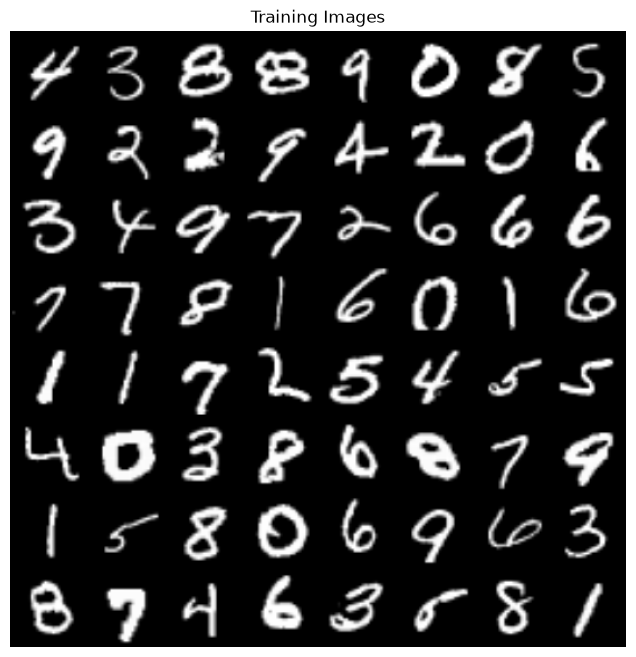

In [5]:
# Decide which device we want to run on
device = torch.device("cuda:0" if (torch.cuda.is_available() and ngpu > 0) else "cpu")

# MNIST database
if not os.path.exists(dataroot):
    os.makedirs(dataroot)

# Download files training.pt and test.pt
dataloader = torch.utils.data.DataLoader(
  dset.MNIST(dataroot, train=True, download=True,
                             transform=transforms.Compose([
                               transforms.Resize(image_size),
                               transforms.ToTensor(),
                               transforms.Normalize(
                                 (0.1307,), (0.3081,))
                             ])),
  batch_size=batch_size,shuffle=True, num_workers=workers)

# Plot some training images
real_batch = next(iter(dataloader))
plt.figure(figsize=(8,8))
plt.axis("off")
plt.title("Training Images")
plt.imshow(np.transpose(vutils.make_grid(real_batch[0].to(device)[:64], padding=2, normalize=True).cpu(),(1,2,0)))

### Arquitectura de red

Con los parámetros de entrada y la base de datos preparada, podemos pasar a la definición del _framework_ que se va a utilizar. Se comienza con la estrategia de inicialización de los pesos de la arquitectura, y después se hablará del generador, el discriminador y las funciones de pérdida.

#### Inicialización de los pesos

Los autores especifican en [3] que todos los pesos del modelo se deben inicializar de manera aleatoria de una distribución normal con media 0 y desviación típica 0.02. La función `weights_init` toma un modelo sin inicializar y re-inicializa todas las capas convolucionales, capas de convoluciones traspuestas y _batch normalization_ para cumplir este criterio. Esta función se aplica a todos los modelos inmediatamente despoués de su creación.

In [6]:
import torch.nn as nn

# Función personalizada de inicialización de pesos
def weights_init(m):
    classname = m.__class__.__name__

    # Inicialización para capas Conv2d y ConvTranspose2d
    if classname.find('Conv') != -1:
        # Los pesos se inicializan con una distribución Normal
        nn.init.normal_(m.weight.data, 0.0, 0.02)

    # Inicialización para capas BatchNorm2d
    elif classname.find('BatchNorm') != -1:
        # Los pesos (gamma) se inicializan con una distribución Normal centrada en 1.0
        nn.init.normal_(m.weight.data, 1.0, 0.02)

        # Los sesgos (beta) se inicializan a cero
        nn.init.constant_(m.bias.data, 0)

#### Generador

El generador $G$ está diseñado para mapear el vector espacial latente $z$ al espacio de datos. Como nuestros datos son imágenes, convertir $z$ al espacio de datos significa crear una imagen RGB con el mismo tamaño que las imágenes de entrenamiento (por ejemplo, 3x64x64). En la práctica, esto se consigue a través de una serie de capas de convoluciones traspuestas 2D con *stride*, cada una de ellas emparejada con una capa de normalización de _batch_ 2D y una activación ReLU. La salida del generador se pasa por una función `tanh` para devolver los datos de salida al rango de entrada de $[-1,1]$. Vale la pena notar la existencia de capas de normalización de _batch_ tras las convoluciones traspuestas, esto es una contribución crítica del artículo [3]. Estas capas ayudan al flujo de gradientes durante el entrenamiento.


Nótese como las entradas que se han definido en la sección de código anterior: *nz*, *ngf* y *nc*, afectan a la arquitectura del generador. El parámetro *nz* es la longitud del vector de entrada, *ngf* se relaciona con la profundidad de los mapas de características a lo largo del generador (hace referencia a la profundidad del último mapa de características) y *nc* es el número de canales en la imagen de salida (3 para imágenes RGB).

In [7]:
import torch.nn as nn
# Asumimos que nz, ngf, y nc están definidos.

class Generator(nn.Module):
    def __init__(self, ngpu):
        super(Generator, self).__init__()
        self.ngpu = ngpu
        self.main = nn.Sequential(
            # input is Z, going into a convolution (nz -> ngf*8)
            nn.ConvTranspose2d( nz, ngf * 8, 4, 1, 0, bias=False), # COMPLETA: in_channels (nz)
            nn.BatchNorm2d(ngf * 8),
            nn.ReLU(True),
            # state size. (ngf*8) x 4 x 4

            # Bloque 2: (ngf*8 -> ngf*4) x 8 x 8
            nn.ConvTranspose2d(ngf * 8, ngf * 4, 4, 2, 1, bias=False), # COMPLETA: out_channels
            nn.BatchNorm2d(ngf * 4),
            nn.ReLU(True),
            # state size. (ngf*4) x 8 x 8

            # Bloque 3: (ngf*4 -> ngf*2) x 16 x 16
            nn.ConvTranspose2d( ngf * 4, ngf * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf * 2), # Módulo de Normalización
            nn.ReLU(True),
            # state size. (ngf*2) x 16 x 16

            # Bloque 4: (ngf*2 -> ngf) x 32 x 32
            nn.ConvTranspose2d( ngf * 2, ngf, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf),
            nn.ReLU(True),
            # state size. (ngf) x 32 x 32

            # Bloque 5: (ngf -> nc) x 64 x 64
            nn.ConvTranspose2d( ngf, nc, 4, 2, 1, bias=False), # out_channels (nc)
            nn.Tanh() # COMPLETA: Función de activación final para el rango [-1, 1]
            # state size. (nc) x 64 x 64
        )

    def forward(self, input):
        return self.main(input)

Se instancia el generador y se aplica la función ``weights_init``. Analice el modelo impreso para entender su estructura.

In [8]:
# Create the generator
netG = Generator(ngpu).to(device)

# Handle multi-gpu if desired
if (device.type == 'cuda') and (ngpu > 1):
    netG = nn.DataParallel(netG, list(range(ngpu)))

# Apply the weights_init function to randomly initialize all weights to mean=0, stdev=0.2.
netG.apply(weights_init)

# Print the model
print(netG)

Generator(
  (main): Sequential(
    (0): ConvTranspose2d(100, 512, kernel_size=(4, 4), stride=(1, 1), bias=False)
    (1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(512, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (7): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (8): ReLU(inplace=True)
    (9): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (10): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (11): ReLU(inplace=True)
    (12): ConvTranspose2d(64, 1, kernel_size=(4, 4), stride=(2, 2), padding

### Discriminador

El discriminador $D$ es una red de clasificación binaria que toma una imagen como entrada y proporciona como salida una probabilidad escalar de que la imagen de entrada sea real (de manera opuesta a que sea *fake*). Aquí, $D$ toma la imagen de entrada 3x64x64, la procesa a partir de una serie de capas Conv2d, BatchNorm2d y LeakyRelu, y proporciona como salida la probabilidad final a través de una función de activación `Sigmoide`. Esta arquitectura se puede extender con más capas si es necesario, pero es importante el uso del _stride_ mayor que 1 en las convoluciones en lugar de usar capas de *max pooling*. De este modo, la red aprende su propia función de *pooling*. Asimismo, las capas de normalización de _batch_ y las activaciones Leaky proporcionan un flujo de gradiente estable, crítico para el proceso de aprendizaje de $G$ y $D$.

In [9]:
import torch.nn as nn
# Asumimos que nc, ndf, y ngpu están definidos.

class Discriminator(nn.Module):
    def __init__(self, ngpu):
        super(Discriminator, self).__init__()
        self.ngpu = ngpu
        self.main = nn.Sequential(
            # Bloque 1: Entrada (nc x 64 x 64) -> (ndf x 32 x 32)
            nn.Conv2d(nc, ndf, 4, 2, 1, bias=False), # COMPLETA: in_channels
            nn.LeakyReLU(0.2, inplace=True),
            # state size. (ndf) x 32 x 32

            # Bloque 2: (ndf -> ndf*2) x 16 x 16
            nn.Conv2d(ndf, ndf * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ndf * 2), # COMPLETA: Módulo de Normalización
            nn.LeakyReLU(0.2, inplace=True),
            # state size. (ndf*2) x 16 x 16

            # Bloque 3: (ndf*2 -> ndf*4) x 8 x 8
            nn.Conv2d(ndf * 2, ndf * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ndf * 4),
            nn.LeakyReLU(0.2, inplace=True),
            # state size. (ndf*4) x 8 x 8

            # Bloque 4: (ndf*4 -> ndf*8) x 4 x 4
            nn.Conv2d(ndf * 4, ndf * 8, 4, 2, 1, bias=False), # COMPLETA: in_channels
            nn.BatchNorm2d(ndf * 8),
            nn.LeakyReLU(0.2, inplace=True),
            # state size. (ndf*8) x 4 x 4

            # Bloque 5: (ndf*8 -> 1) x 1 x 1
            nn.Conv2d(ndf * 8, 1, 4, 1, 0, bias=False), # COMPLETA: out_channels
            nn.Sigmoid() # COMPLETA: Función de activación final para obtener probabilidad [0, 1]
        )

    def forward(self, input):
        # Aplanar la salida para obtener un único valor de probabilidad (real vs. fake)
        return self.main(input)

Ahora, como con el generador, se crea el discriminador y se aplica la función ``weights_init``.

In [10]:
# Create the Discriminator
netD = Discriminator(ngpu).to(device)

# Handle multi-gpu if desired
if (device.type == 'cuda') and (ngpu > 1):
    netD = nn.DataParallel(netD, list(range(ngpu)))

# Apply the weights_init function to randomly initialize all weights to mean=0, stdev=0.2.
netD.apply(weights_init)

# Print the model
print(netD)

Discriminator(
  (main): Sequential(
    (0): Conv2d(1, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (1): LeakyReLU(negative_slope=0.2, inplace=True)
    (2): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (4): LeakyReLU(negative_slope=0.2, inplace=True)
    (5): Conv2d(128, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (6): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (7): LeakyReLU(negative_slope=0.2, inplace=True)
    (8): Conv2d(256, 512, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (9): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): LeakyReLU(negative_slope=0.2, inplace=True)
    (11): Conv2d(512, 1, kernel_size=(4, 4), stride=(1, 1), bias=False)
    (12): Sigmoid()
  )

#### Funciones de pérdida y optimizadores

Con $D$ y $G$ definidas, se puede definir el proceso de aprendizaje a través de las funciones de pérdida y optimizadores. Se utilizará la función BCELoss (cross-entropía binaria) tal y como se define en Pytorch (véase https://pytorch.org/docs/stable/nn.html#torch.nn.BCELoss):


\begin{align}\ell(x, y) = L = \{l_1,\dots,l_N\}^\top, \quad l_n = - \left[ y_n \cdot \log p(y_n) + (1 - y_n) \cdot \log (1 - p(y_n)) \right]\end{align}

Nótese como la función proporciona el cálculo de ambas componentes *log* en la función objetivo (por ejemplo, $log(D(x))$ and $log(1-D(G(z)))$). Se puede especificar qué parte de la ecuación BCE utilizar con la entrada $y$. Esto se realiza en el bucle de entrenamiento que se describirá a continuación, pero es importante entender cómo se puede elegir cada componente que se quiere calcular sólo con cambiar $y$ (las etiquetas *ground-truth*).

A continuación, se define la etiqueta real como 1 y la etiqueta _fake_ como 0. Estas etiquetas se utilizarán cuando se calculen las funciones de pérdida de $D$ y $G$, y esta es la convención que se utiliza en el artículo original sobre GANs [1]. Finalmente, se especifican dos optimizadores separados, uno para la red de generación $G$ y otro para la red de discriminación $G$. Como se especifica en [3], ambos son optimizadores Adam con tasa de aprendizaje 0.0002 y Beta1 = 0.5 (para nuestro caso la tasa de aprendizaje es distinta). Para visualizar la progresión del aprendizaje de la red, se genera un _batch_ fijo de vectores latentes que se extraen de una distribución Gaussiana (ruido fijo). En el bucle de entrenamiento, periódicamente se pone como entrada a $G$ este ruido fijo, y a medida que avanza el proceso de aprendizaje se puede ver las imágenes que forma ese ruido.

In [11]:
# Initialize BCELoss function
criterion = nn.BCELoss()

# Create batch of latent vectors that we will use to visualize
#  the progression of the generator
fixed_noise = torch.randn(64, nz, 1, 1, device=device)

# Establish convention for real and fake labels during training
real_label = 1.
fake_label = 0.

# Setup Adam optimizers for both G and D
optimizerD = optim.Adam(netD.parameters(), lr=lr, betas=(beta1, 0.999))
optimizerG = optim.Adam(netG.parameters(), lr=lr, betas=(beta1, 0.999))

### Entrenamiento

Por último, ahora que se tienen todas las partes del _framework_ GAN definidas, se puede entrenar el mismo. El entrenamiento de las GANs es un proceso __COMPLEJO__, ya que una selección de hiperparámetros incorrecta puede conducir a un no entrenamiento de la misma o al *mode collapse* (es decir, el generador colapsa y solo es capaz de ofrecer un número limitado de *fakes*) sin ninguna explicación válida de por qué ocurre esto. Aquí se seguirá el algoritmo 1 del artículo de Goodfellow [1], acatando el código Ganhacks de buenas prácticas de entrenamiento, del que se dispone en [6]. De este modo, se construirán diferentes *mini-batches* para imágenes reales y *fake*, y se ajustará la función objetivo de $G$ para maximizar $logD(G(z))$. El proceso de entrenamiento se divide en dos partes. La parte 1 actualiza el discriminador y la parte 2 actualiza el generador.

**Parte 1 - Entrenando el Discriminador**

El objetivo del entrenamiento del discriminador es maximizar la probabilidad de clasificar correctamente una imagen de entrada como imagen real o sintética. En palabras de Goodfellow, queremos "actualizar el discriminador haciendo ascender su gradiente estocástico". En la práctica, queremos maximizar $log(D(x)) + log(1-D(G(z)))$. Debido a la sugerencia de *mini-batches* separados de Ganhacks, se calculará esto en dos pasos. Primero, se construye un _batch_ de muestras reales de la base de datos de entrenamiento y se realiza el _forward_ a través de $D$, se calcula la pérdida ($log(D(x))$) y se calculan los gradientes con el método _backward_. Segundo, se construye un _batch_ de muestras sintéticas con el generador, se realiza el _forward_ a través de $D$, se calcula la pérdida ($log(1-D(G(z)))$) y se *acumulan* los gradientes con el _backward_. Una vez se tienen los gradientes acumulados de los _batches_ todo-real y todo-*fake*, se considera que se ha realizado un paso del optimizador del discriminador.

**Parte 2 - Entrenando el Generador**

Como se especifica en el artículo original [1], se quiere entrenar el generador minimizando $log(1-D(G(z)))$ en un esfuerzo por generar mejores *fakes*. Sin embargo, Goodfellow demostró que esto no proporciona suficientes gradientes, especialmente en los primeros pasos de entrenamiento. Como solución, se intenta maximizar $log(D(G(z)))$. En el código esto se consigue: clasificando la salida del generador de la parte 1 con el discriminador, calculando la pérdida de $G$ *usando las etiquetas reales como ground-truth*, computando los gradientes de $G$ con un _backward_ y actualizando los parámetros de $G$ con un paso del optimizador. Puede parece contra-intuitivo usar las etiquetas reales como etiquetas *ground-truth* para la función de pérdida, pero esto nos permite usar la parte $log(x)$ de la BCELoss (en lugar de usar la parte $log(1-x)$), que es exactamente lo que queremos.

Finalmente, se reportan las estadísticas y al final de cada _epoch_ se utilizará el _batch_ de vectores de ruido fijo para visualizar el progreso del aprendizaje de $G$. Las estadísticas que se reportan son:

-  **Loss_D** - pérdida del discriminador calculada como la suma de las pérdidas para los _batches_ todo-real y todo-*fake* ($log(D(x)) + log(D(G(z)))$).
-  **Loss_G** - pérdida del generador calculada como $log(D(G(z)))$.
-  **D(x)** - la salida media (a lo largo del *batch*) del discriminador para el *batch* todo-real. Debe comenzar próxima a 1 y en teoría converger a 0.5 a medida que $G$ va mejorando. Piense por qué ocurre esto.
-  **D(G(z))** - la salida media (a lo largo del *batch*) del discriminador para el *batch* todo-*fake*. El primer número es antes de que $D$ se actualice y el segundo número es después de que $D$ se actualice. Estos números deben comenzar próximos a 0 y converger a 0.5 a medida que $G$ comienza a mejorar. Piense por qué ocurre esto.


****IMPORTANTE**. Este paso puede tardar, dependiendo de cuántos _epochs_ realizar y si se eliminaron algunas muestras de la base de datos.

In [12]:
# Training Function
def train_gan(netD, netG, dataloader,optimizerD, optimizerG, num_epochs=5,results_dir='results',manualSeed=1):

    # Lists to keep track of progress
    img_list    = []
    G_losses    = []
    D_losses    = []
    iters = 0

    print("Starting Training Loop...")
    # For each epoch
    for epoch in range(num_epochs):
        # For each batch in the dataloader
        for i, data in enumerate(dataloader, 0):

            ############################
            # (1) Actualizar la red D: maximizar log(D(x)) + log(1 - D(G(z)))
            ###########################

            ## Entrenar con el lote REAL
            netD.zero_grad()
            # Formato del lote
            real_cpu = data[0].to(device)
            b_size = real_cpu.size(0)
            label = torch.full((b_size,), real_label, device=device)
            # Forward pass del lote real a través de D
            output = netD(real_cpu).view(-1)
            # Calcular la pérdida en el lote real
            errD_real = criterion(output, label)
            # Calcular gradientes para D en backward pass
            errD_real.backward()
            D_x = output.mean().item()

            ## Entrenar con el lote FALSO
            # Generar lote de vectores de ruido latente
            noise = torch.randn(b_size, nz, 1, 1, device=device) # COMPLETA: b_size, nz
            # Generar lote de imágenes falsas con G
            fake = netG(noise)
            # Etiquetar los datos generados como FALSOS
            label.fill_(fake_label) # COMPLETA: fake_label
            # Clasificar el lote falso con D (detaching para no calcular gradientes en G)
            output = netD(fake.detach()).view(-1)
            # Calcular la pérdida de D en el lote falso
            errD_fake = criterion(output, label)
            # Calcular los gradientes para este lote
            errD_fake.backward()
            D_G_z1 = output.mean().item()
            # Sumar los gradientes
            errD = errD_real + errD_fake
            # Actualizar D
            optimizerD.step() # COMPLETA: La función para realizar el paso de optimización de D

            ############################
            # (2) Actualizar la red G: maximizar log(D(G(z)))
            ###########################
            netG.zero_grad()
            # El generador quiere que D clasifique las falsas como REALES
            label.fill_(real_label)  # COMPLETA: real_label

            # Forward pass del lote falso a través de D (usando 'fake' generado previamente)
            output = netD(fake).view(-1)
            # Calcular la pérdida de G basada en esta salida
            errG = criterion(output, label)
            # Calcular gradientes para G
            errG.backward()
            D_G_z2 = output.mean().item()
            # Actualizar G
            optimizerG.step() # COMPLETA: La función para realizar el paso de optimización de G

            # [El código de logging, guardado y suavizado de pérdidas permanece sin cambios]

            # Output training stats
            if i % 50 == 0:
                print('[%d/%d][%d/%d]\tLoss_D: %.4f\tLoss_G: %.4f\tD(x): %.4f\tD(G(z)): %.4f / %.4f'
                      % (epoch, num_epochs, i, len(dataloader),
                         errD.item(), errG.item(), D_x, D_G_z1, D_G_z2))

            # Save Losses for plotting later
            G_losses.append(errG.item())
            D_losses.append(errD.item())

            # Check how the generator is doing by saving G's output on fixed_noise
            if (iters % 50 == 0) or ((epoch == num_epochs-1) and (i == len(dataloader)-1)):
                with torch.no_grad():
                    fake = netG(fixed_noise).detach().cpu()
                img_list.append(vutils.make_grid(fake, padding=2, normalize=True))

            iters += 1
        # Save results for each epoch
        if not os.path.exists(results_dir):
            os.makedirs(results_dir)
        with torch.no_grad():
            fake = netG(fixed_noise).detach().cpu()
        img_grid=np.array(255.0*np.transpose(vutils.make_grid(fake, padding=2, normalize=True),(1,2,0))).astype(np.uint8)
        cv2.imwrite(os.path.join(results_dir,'epoch_'+str(epoch)+'.png'),cv2.cvtColor(img_grid, cv2.COLOR_RGB2BGR))


    # For the purpose of representation, we implement a moving average filter to reduce the noise:
    # consecutive iterations can have very different loss values but we are interested in their trend
    N = 20
    cumsumD, moving_avesD = [0], []
    cumsumG, moving_avesG = [0], []

    for i, x in enumerate(D_losses, 1):
        cumsumD.append(cumsumD[i-1] + x)
        if i>=N:
            moving_aveD = (cumsumD[i] - cumsumD[i-N])/N
            moving_avesD.append(moving_aveD)

    for i, x in enumerate(G_losses, 1):
        cumsumG.append(cumsumG[i-1] + x)
        if i>=N:
            moving_aveG = (cumsumG[i] - cumsumG[i-N])/N
            moving_avesG.append(moving_aveG)
    return (moving_avesD, moving_avesG, img_list)
    #return (D_losses, G_losses, img_list)

## Parte 3. Experimentos.

### 1. Análisis de un entrenamiento correcto.

- Analice cómo las funciones de pérdida de $D$ y $G$ cambian durante el entrenamiento.

****IMPORTANTE**. El valor de learning rate que se os proporciona en la práctica (0.005) es elevado. Es posible que con un valor más pequeño de la tasa de aprendizaje (por ejemplo, 0.001) los resultados sean mejores y las funciones de pérdida evolucionen de manera más suave, pero no está garantizada la convergencia del algoritmo para el caso de los dígitos, es posible que tengáis que hacer varias pruebas.
Tened en cuenta esta información a la hora de realizar vuestra parte de trabajo autónomo, sobre todo si cambiáis de base de datos. Es posible que tengáis que probar diversas tasas de aprendizaje hasta entrenar adecuadamente la red.

In [13]:
# Training stage
baseline_dir=os.path.join('results','baseline')
if not os.path.exists(baseline_dir):
    os.makedirs(baseline_dir)

[D_losses,G_losses,img_list]= train_gan(netD, netG, dataloader, optimizerD, optimizerG,
                                         num_epochs=num_epochs, results_dir=baseline_dir, manualSeed=manualSeed)

state = {'state_dict': netD.state_dict(),}
torch.save(state, os.path.join(baseline_dir,'netD.pth'))
state = {'state_dict': netG.state_dict(),}
torch.save(state, os.path.join(baseline_dir,'netG.pth'))
np.save(os.path.join(baseline_dir,'G_losses.npy'),np.array(G_losses))
np.save(os.path.join(baseline_dir,'D_losses.npy'),np.array(D_losses))

Starting Training Loop...


[0/5][0/469]	Loss_D: 2.0549	Loss_G: 29.9719	D(x): 0.3956	D(G(z)): 0.5588 / 0.0000


[0/5][50/469]	Loss_D: 2.4729	Loss_G: 7.1336	D(x): 0.9164	D(G(z)): 0.6148 / 0.1345


[0/5][100/469]	Loss_D: 2.1091	Loss_G: 6.0699	D(x): 0.8376	D(G(z)): 0.7138 / 0.0192


[0/5][150/469]	Loss_D: 1.1283	Loss_G: 4.7714	D(x): 0.8501	D(G(z)): 0.4916 / 0.0181


[0/5][200/469]	Loss_D: 2.1752	Loss_G: 1.3164	D(x): 0.2147	D(G(z)): 0.0245 / 0.3494


... (42 outputs left out)

[4/5][300/469]	Loss_D: 2.3229	Loss_G: 0.9423	D(x): 0.1376	D(G(z)): 0.1296 / 0.4103


[4/5][350/469]	Loss_D: 0.0352	Loss_G: 3.8561	D(x): 0.9967	D(G(z)): 0.0314 / 0.0267


[4/5][400/469]	Loss_D: 0.0050	Loss_G: 5.7868	D(x): 0.9992	D(G(z)): 0.0042 / 0.0042


[4/5][450/469]	Loss_D: 0.0015	Loss_G: 8.1007	D(x): 0.9988	D(G(z)): 0.0004 / 0.0003


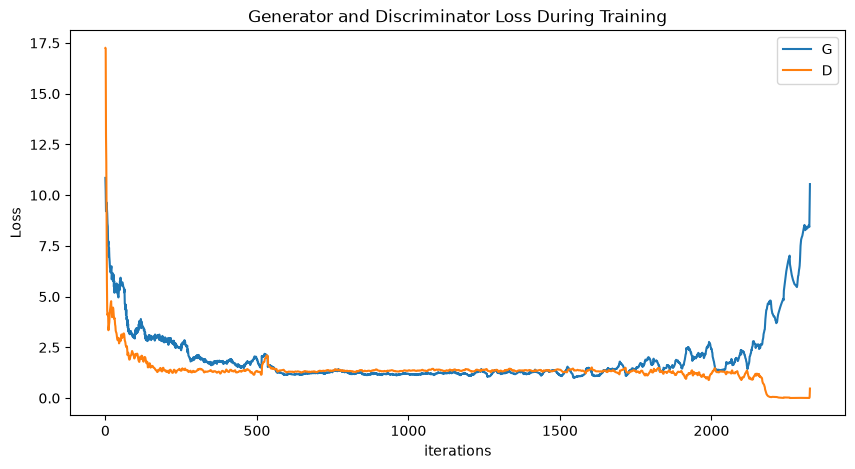

In [14]:
# Loss versus training iteration
plt.figure(figsize=(10,5))
plt.title("Generator and Discriminator Loss During Training")
plt.plot(G_losses,label="G")
plt.plot(D_losses,label="D")
plt.xlabel("iterations")
plt.ylabel("Loss")
plt.legend()
plt.show()

**Análisis de las funciones de pérdida (lr = 0.005).** Se distinguen tres fases:

1. **Inicio (primeras ~200 iteraciones):** pérdidas muy grandes e inestables (la media móvil llega a ≈17). Con una tasa de aprendizaje tan alta, ambas redes dan pasos enormes y el juego oscila con fuerza.
2. **Fase de equilibrio (≈ iteraciones 300-2150, epochs 1-4):** las dos pérdidas se estabilizan y oscilan alrededor de valores parecidos (media ≈1.37 para $D$ y ≈1.26 para $G$). No tienden a cero porque es un juego de dos jugadores: cuando uno mejora, la pérdida del otro sube. En esta fase $D(x)$ y $D(G(z))$ oscilan alrededor de 0.4-0.7, cerca del equilibrio teórico de 0.5, y el generador produce dígitos reconocibles (ver `results/baseline/epoch_1.png` a `epoch_3.png`).
3. **Fallo (último epoch, a partir de la iteración ≈2150):** el entrenamiento diverge. La pérdida de $D$ cae a ≈0.02 ($D(x)\to 1$, $D(G(z))\to 0$) y la de $G$ se dispara (≈7.5 de media al final, picos de ≈11). El discriminador gana por completo: es el problema de *diminished gradient*. Al mismo tiempo, el generador sufre un ***mode collapse* total** y produce la misma imagen (una textura sin forma de dígito) para cualquier ruido de entrada.

Este comportamiento confirma el aviso del enunciado: lr = 0.005 es demasiado alto y el algoritmo no converge de forma estable. Con un valor menor (p. ej. 0.001 o el 0.0002 del artículo DCGAN) las pérdidas evolucionarían de forma más suave.

- Visualice las salidas de $G$ para el _batch_ de ruido fijo para cada _epoch_ con una animación.

In [15]:
#%%capture
fig = plt.figure(figsize=(8,8))
plt.axis("off")
ims = [[plt.imshow(np.transpose(i,(1,2,0)), animated=True)] for i in img_list]
ani = animation.ArtistAnimation(fig, ims, interval=1000, repeat_delay=1000, blit=True)

plt.close(fig)
HTML(ani.to_jshtml())

Animation size has reached 21428923 bytes, exceeding the limit of 20971520.0. If you're sure you want a larger animation embedded, set the animation.embed_limit rc parameter to a larger value (in MB). This and further frames will be dropped.


**Animación.** Los primeros fotogramas son ruido; tras unas 50-100 iteraciones aparecen manchas centrales y, a lo largo del epoch 1, los trazos se convierten en dígitos. Durante los epochs 1-3 cada vector de ruido fijo genera un dígito concreto que va mejorando poco a poco y se mantiene estable: el mismo $z$ produce el mismo dígito. En el último epoch todas las imágenes se convierten de repente en la misma textura (*mode collapse*).

*Nota:* la animación completa supera el límite de 20 MB que matplotlib permite incrustar (`animation.embed_limit`), así que los últimos fotogramas no se incluyen en el notebook guardado. Las imágenes de cada epoch están en `results/baseline/epoch_*.png`.

- Observe un _batch_ de datos reales en comparación con un _batch_ de datos *fake*. ¿Son realistas estos últimos?

In [16]:
print(len(img_list))
print(iter)

48
<built-in function iter>


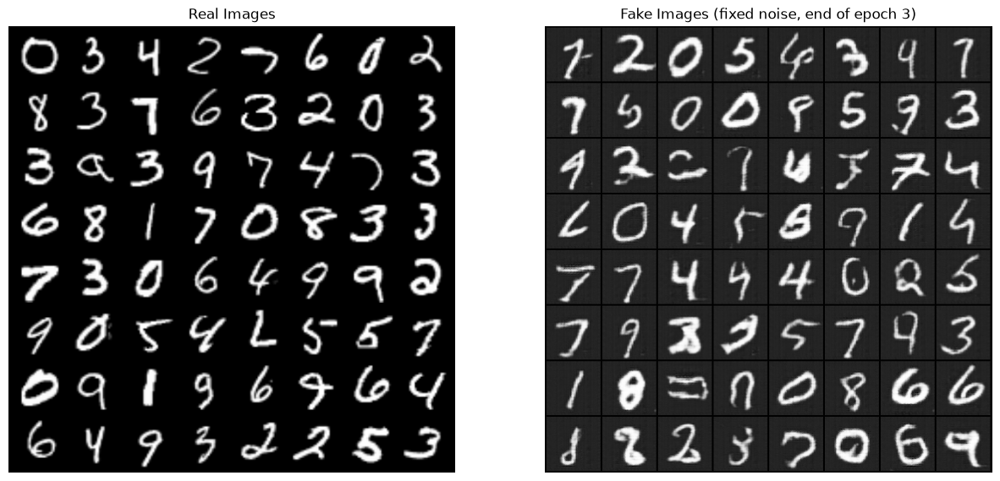

In [17]:
# Grab a batch of real images from the dataloader
real_batch = next(iter(dataloader))

# Plot the real images
plt.figure(figsize=(15,15))
plt.subplot(1,2,1)
plt.axis("off")
plt.title("Real Images")
plt.imshow(np.transpose(vutils.make_grid(real_batch[0].to(device)[:64], padding=5, normalize=True).cpu(),(1,2,0)))

# Plot the fake images of intermediate iteration
# Con lr = 0.005 el generador colapsa en el último epoch, así que la mejor generación es una
# intermedia: se usa la imagen del ruido fijo guardada al final del epoch 3 (results/baseline/epoch_3.png).
plt.subplot(1,2,2)
plt.axis("off")
plt.title("Fake Images (fixed noise, end of epoch 3)")
img_epoch3 = cv2.cvtColor(cv2.imread(os.path.join(baseline_dir, 'epoch_3.png')), cv2.COLOR_BGR2RGB)
plt.imshow(img_epoch3) # para iteracion intermedia generación buena
plt.show()

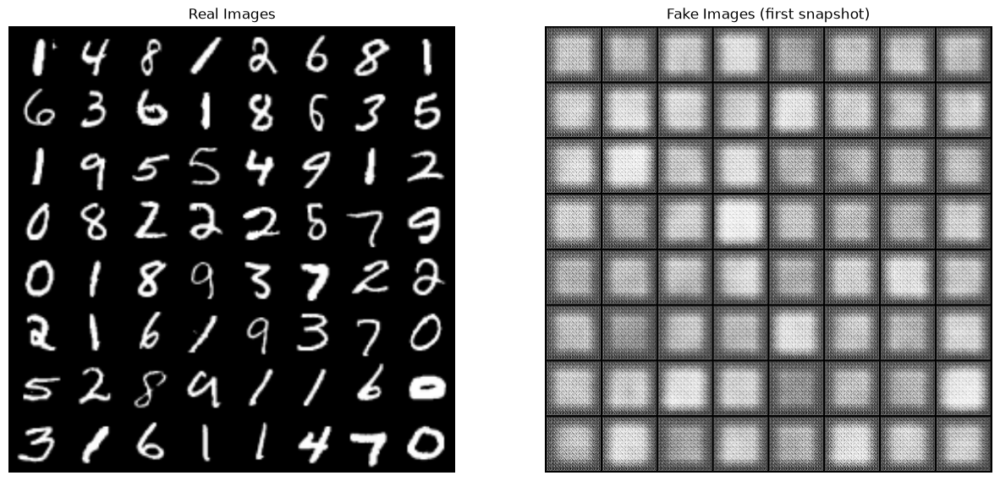

In [18]:
# Plot the real images
plt.figure(figsize=(15,15))
plt.subplot(1,2,1)
plt.axis("off")
plt.title("Real Images")
plt.imshow(np.transpose(vutils.make_grid(real_batch[0].to(device)[:64], padding=5, normalize=True).cpu(),(1,2,0)))

# Plot the fake images from the first epoch
plt.subplot(1,2,2)
plt.axis("off")
plt.title("Fake Images")
plt.title("Fake Images (first snapshot)")
plt.imshow(np.transpose(img_list[0],(1,2,0))) # para iteracion inicial > ruido
plt.show()

**¿Son realistas las imágenes *fake*?** En la iteración intermedia buena (final del epoch 3) sí lo son en gran medida: la mayoría se reconocen como dígitos (0, 1, 2, 4, 5, 6, 7, 9...), con trazos continuos, grosor parecido al real y fondo negro limpio. Aun así se distinguen de las reales: algunos trazos están rotos o tienen pequeñas manchas, y unos pocos dígitos son ambiguos o deformes (mezclas entre 3/8, 4/9 o 7/1). La primera instantánea (iteración 0) es puro ruido, unas manchas grises sin estructura, porque el generador aún no ha aprendido nada. En la iteración final, el generador colapsado produce 64 copias de una misma textura que no se parece a ningún dígito.

- Se van a generar otros *batches* de imágenes *fake* a partir de muestras de ruido aleatorio. Analice los resultados. ¿Qué dígitos son más reconocibles? ¿Hay algunos que no se generan correctamente?

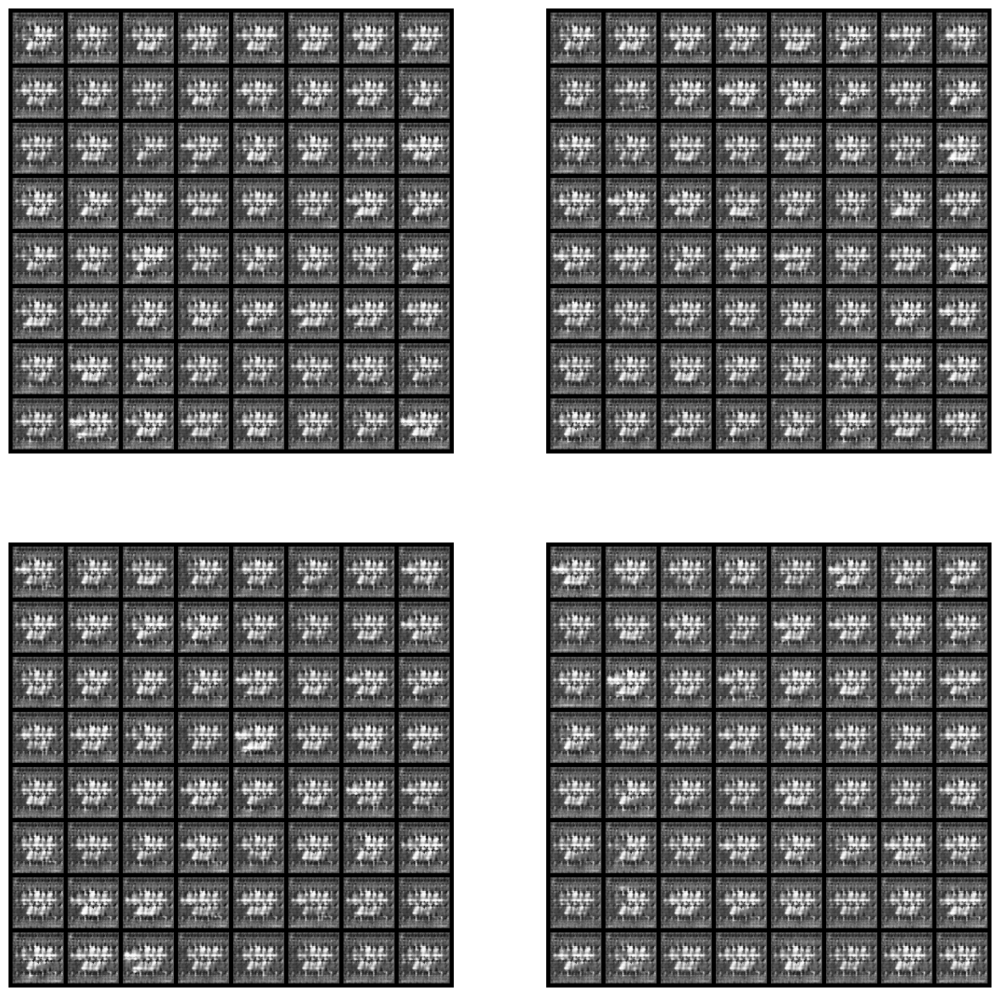

In [19]:
plt.figure(figsize=(15,15))

for i in range(4):
    with torch.no_grad():
        random_noise = torch.randn(64, nz, 1, 1, device=device)
        fake = netG(random_noise).detach().cpu()
    plt.subplot(2,2,i+1)
    plt.axis("off")
    plt.imshow(np.transpose(vutils.make_grid(fake[:64], padding=5, normalize=True).cpu(),(1,2,0)))
plt.show()

**Resultados con ruido aleatorio.** Como el generador final está **colapsado**, en los cuatro *batches* aparece la misma imagen (una textura gris con manchas) para los 256 vectores de ruido distintos: **ningún dígito es reconocible** y no se genera ninguno correctamente. Es un ejemplo extremo de *mode collapse*: el generador ha ignorado el ruido de entrada y se ha quedado en un único "modo" que, en el último momento, engañaba al discriminador.

Con el generador de una iteración intermedia (epochs 2-3, ver `results/baseline/epoch_2.png` y `epoch_3.png`), los dígitos más reconocibles eran los de forma simple y trazo único: **0, 1, 7, 9 y 6**. Los que salían peor eran los de forma más compleja o fácil de confundir: **8, 3, 5, 2 y 4** (por ejemplo 8 con lazos abiertos o 4 que parecen 9).

- ¿Qué ocurre si se ponen a 0 o a un valor fijo algunas de las entradas de ruido blanco del generador? ¿Para cada valor de entrada, la red proporciona un solo modo o varios modos distintos?

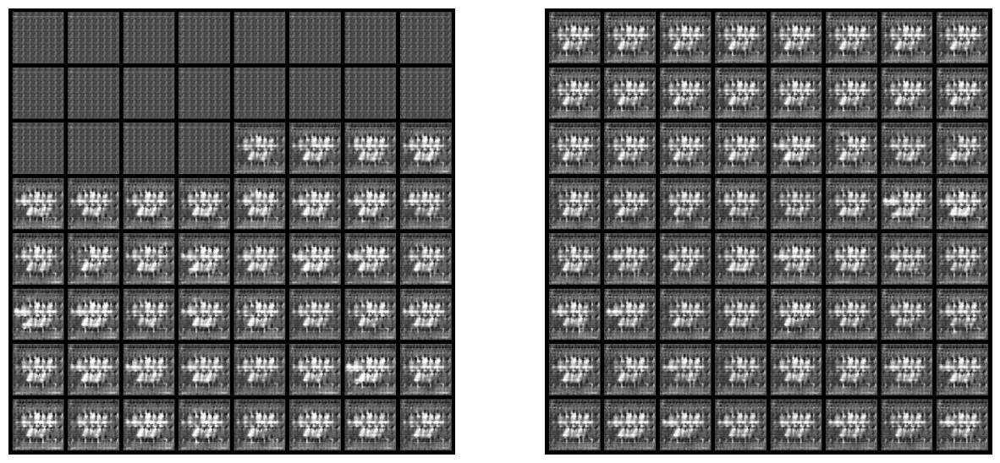

In [20]:
# We put some dimensions to 0
random_noise = torch.randn(64, nz, 1, 1, device=device)
# We put random elements to 0
for i in range(20):
    #COMPLETAR: establecer el vector de ruido para esas 20 muestras a cero
    random_noise[i,:,:,:] = 0

with torch.no_grad():
    fake = netG(random_noise).detach().cpu()
plt.figure(figsize=(15,15))
plt.subplot(1,2,1)
plt.axis("off")
plt.imshow(np.transpose(vutils.make_grid(fake[:64], padding=5, normalize=True).cpu(),(1,2,0)))
# We fix a lot of elements with the same value
random_noise = torch.randn(64, nz, 1, 1, device=device)
for i in range(20):
    #COMPLETAR: fijar el vector de ruido para esas 20 muestras a un valor (-1)
    random_noise[i,:,:,:] = -1
with torch.no_grad():
    fake = netG(random_noise).detach().cpu()
plt.subplot(1,2,2)
plt.axis("off")
plt.imshow(np.transpose(vutils.make_grid(fake[:64], padding=5, normalize=True).cpu(),(1,2,0)))
plt.show()

**Ruido a cero o a un valor fijo.** En ambas mitades de la figura, las 20 primeras muestras (vector de ruido completo a 0 o a −1) dan **exactamente la misma imagen** entre sí, porque el generador es una **función determinista**: para cada valor de entrada produce **una sola salida (un único modo)**. Toda la variabilidad de una GAN procede del ruido $z$. Con el vector a 0 la imagen es más tenue (en la figura, las primeras muestras salen grises/oscuras), ya que $z=0$ está muy lejos de los vectores que el generador vio en el entrenamiento ($\|z\| \approx \sqrt{100}=10$).

Como el generador final está colapsado, el resto de muestras (ruido aleatorio) también producen prácticamente la misma imagen: el colapso hace que la salida apenas dependa de la entrada. Con un generador bien entrenado, las muestras con ruido aleatorio serían dígitos diferentes, mientras que las fijadas seguirían siendo idénticas entre sí.

- En GANs no se calcula específicamente una representación latente a partir de los datos reales, con lo que no se puede hacer directamente la mezcla de dos muestras de ruido de entrada para producir una señal de salida mezcla de ambas. Sin embargo, si se toman dos muestras de ruido y su suma, ¿la imagen resultante es una mezcla de las otras dos imágenes? ¿Contiene componentes de ambas imágenes?

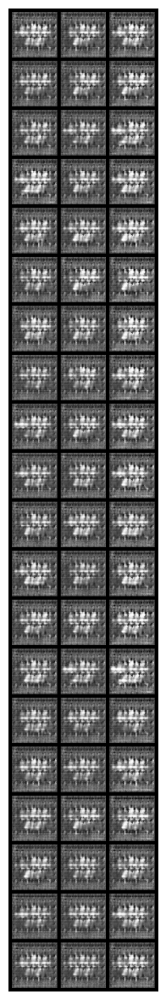

In [21]:
random_noise = torch.randn(64, nz, 1, 1, device=device)
# We change the sample to the structure: sample1-sample2-sum2//sample1-sample2-sum//...
for i in range (2,64,3):
    random_noise[i,:,:,:]=random_noise[i-1,:,:,:]+random_noise[i-2,:,:,:]

with torch.no_grad():
    fake = netG(random_noise).detach().cpu()
plt.figure(figsize=(15,15))
plt.axis("off")
plt.imshow(np.transpose(vutils.make_grid(fake[:60], nrow=3,padding=5, normalize=True).cpu(),(1,2,0)))
plt.show()

**Suma de dos muestras de ruido.** En general, $G(z_1+z_2)$ **no es una mezcla** de $G(z_1)$ y $G(z_2)$. Una GAN no aprende un espacio latente lineal en el que sumar vectores combine las imágenes, y además $z_1+z_2$ tiene norma ≈14, fuera de la región en la que se entrenó el generador (≈10). Lo esperable con un generador bien entrenado es un dígito nuevo, a veces con algún rasgo de uno de los dos, pero no una superposición de ambos (en `GAN_notebook.ipynb`, apartado 3.4, se comprueba con un generador bien entrenado: $G(a+b)$ es otro dígito distinto).

Aquí, al estar el generador colapsado, las tres columnas (muestra 1, muestra 2 y suma) dan la misma imagen, así que el experimento no permite ver ninguna mezcla.

### 2. Problems with GANs.

#### _Mode collapse_

El _mode collapse_ es uno de los problemas más difíciles de resolver con GANs. Las distribuciones de datos reales son multi-modales. Por ejemplo, en la base de datos MNIST se tienen 10 clases (dígitos manuscritos de 0 a 9). El _mode collapse_ hace referencia a un problema de entrenamiento de las GANs según el cual la red generativa sólo es capaz de producir uno de los modos de la distribución o una mezcla de los modos de la distribución.




Este problema de entrenamiento es bastante común, como también es usual que se produzca un *partial collapse*, es decir, que la red produzca imágenes sintéticas que responden a pocos modos.


**Lo que se ha observado en este entrenamiento.** Con lr = 0.005, el generador pasó en el último epoch de producir dígitos variados a generar **una única imagen para cualquier ruido de entrada**: un *mode collapse* completo, que se puede ver en `results/baseline/epoch_3.png` frente a `epoch_4.png`. Coincide con la divergencia de las pérdidas: el discriminador aprende a rechazar fácilmente esa imagen, el generador no consigue salir del modo en el que ha caído y el entrenamiento ya no se recupera. Antes del colapso total también había un *partial collapse* leve: algunos dígitos (0, 1, 7, 9) aparecían con más frecuencia y mejor definidos que otros (8, 3, 5).

#### _Diminished gradient_

Otro de los problemas principales que se producen a la hora de entrenar una GAN es el _diminished gradient_. Esto ocurre cuando el discriminador es tan bueno que el gradiente en el generador se desvanece y no se aprende nada, es decir, el generador no se actualiza de manera suficiente como para proporcionar buenos _fakes_.



**Lo que se ha observado en este entrenamiento.** Es lo que ocurre al final: $D(x)\approx 1$ y $D(G(z))\approx 0$ (la pérdida de $D$ cae a ≈0.002-0.02). El discriminador es casi perfecto, la salida de su sigmoide está saturada y el gradiente que llega al generador es muy pequeño. La pérdida de $G$ crece sin parar (hasta ≈8-11) y el generador ya no mejora. Una tasa de aprendizaje más pequeña, la etiqueta real suavizada (*one-sided label smoothing*, p. ej. 0.9) o pérdidas como la de WGAN-GP ayudan a evitarlo.

Aparte de la no convergencia, el *mode collapse* y el *diminished gradient* son los problemas más usuales al entrenar GANs.